# Лабораторная работа 2 · YOLO26 на Android (вариант 1)

**Задача:** обучить YOLO26n детектировать **зубную щётку, тюбик зубной пасты и твёрдое мыло** (опционально — 4-й класс: тара жидкого мыла), экспортировать модель в LiteRT и запустить её в Android-приложении.

| Шаг | Что делаем |
|---|---|
| 1 | Подготовка окружения и данных |
| 2 | Эксперимент 1 — 3 класса (`v1_3cls`) |
| 3 | Эксперимент 2 — 4 класса с жидким мылом (`v2_4cls`) |
| 4 | Сравнение экспериментов |
| 5 | Экспорт в LiteRT и проверка выхода модели |
| 6 | Сохранение результатов |

**Датасет** собран скриптом `scripts/merge_datasets.py` из пяти наборов Roboflow Universe (лицензия CC BY 4.0, источники указаны в `docs/ATTRIBUTION.md`).
Размеченный набор для воспроизведения: **https://github.com/dareart03/lab2_NN/releases/tag/dataset-v2 / `prepared_4cls.zip`**.

> Запускать нужно на GPU: *Среда выполнения → Сменить тип среды → T4 GPU*.

## 1. Окружение и данные

In [ ]:
import torch; print(torch.cuda.is_available())

True


Распаковываем подготовленный датасет. Архив `prepared.zip` загружен в файлы Colab (папка `/content`); структура внутри: `images/{train,val}`, `labels/{train,val}`.
Файлы Colab пропадают при сбросе среды, поэтому архив лучше держать ещё и на Google Drive.

In [ ]:
!unzip -q /content/prepared.zip -d /content/prepared
!ls /content/prepared

data.yaml  docker_data.yaml  images  labels


Конфиг данных для Colab пишем заново: в `data.yaml` из архива записан путь с моего компьютера.
Порядок классов фиксирован: `0 — toothbrush, 1 — toothpaste, 2 — soap`.

In [ ]:
import yaml
cfg = dict(path='/content/prepared', train='images/train', val='images/val',
           names={0: 'toothbrush', 1: 'toothpaste', 2: 'soap'})
yaml.safe_dump(cfg, open('/content/data.yaml', 'w'))

## 2. Эксперимент 1 — три класса (`v1_3cls`)

Модель `yolo26n.pt`, 100 эпох, размер 640, батч 16, ранняя остановка по 25 эпохам без улучшения, `seed=42` для воспроизводимости.
Результаты сохраняются в `/content/runs/v1_3cls`.

In [ ]:
!pip install ultralytics -qqq
!yolo detect train model=yolo26n.pt data=/content/data.yaml epochs=100 imgsz=640 batch=16 patience=25 seed=42 device=0 project=/content/runs name=v1_3cls

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=Non

**Итог (валидация, 189 изображений):**

| Класс | P | R | mAP50 | mAP50-95 |
|---|---|---|---|---|
| all | 0.822 | 0.815 | **0.851** | 0.649 |
| toothbrush | 0.740 | 0.823 | 0.848 | 0.620 |
| toothpaste | 0.861 | 0.875 | 0.898 | 0.626 |
| soap | 0.866 | 0.747 | 0.807 | 0.700 |

Обучение заняло 0.53 ч на T4. Валидация берётся из тех же источников, что и train, поэтому окончательную оценку нужно делать на собственных тестовых фото.

In [ ]:
!unzip -q /content/v1_3cls_results.zip -d /content/v1_3cls_results
!ls /content/v1_3cls_results

content


In [ ]:
!ls /content/v1_3cls_results/content/runs/v1_3cls/

args.yaml			 results.csv	      val_batch0_labels.jpg
BoxF1_curve.png			 results.png	      val_batch0_pred.jpg
BoxP_curve.png			 train_batch0.jpg     val_batch1_labels.jpg
BoxPR_curve.png			 train_batch1.jpg     val_batch1_pred.jpg
BoxR_curve.png			 train_batch2.jpg     val_batch2_labels.jpg
confusion_matrix_normalized.png  train_batch6120.jpg  val_batch2_pred.jpg
confusion_matrix.png		 train_batch6121.jpg  weights
labels.jpg			 train_batch6122.jpg


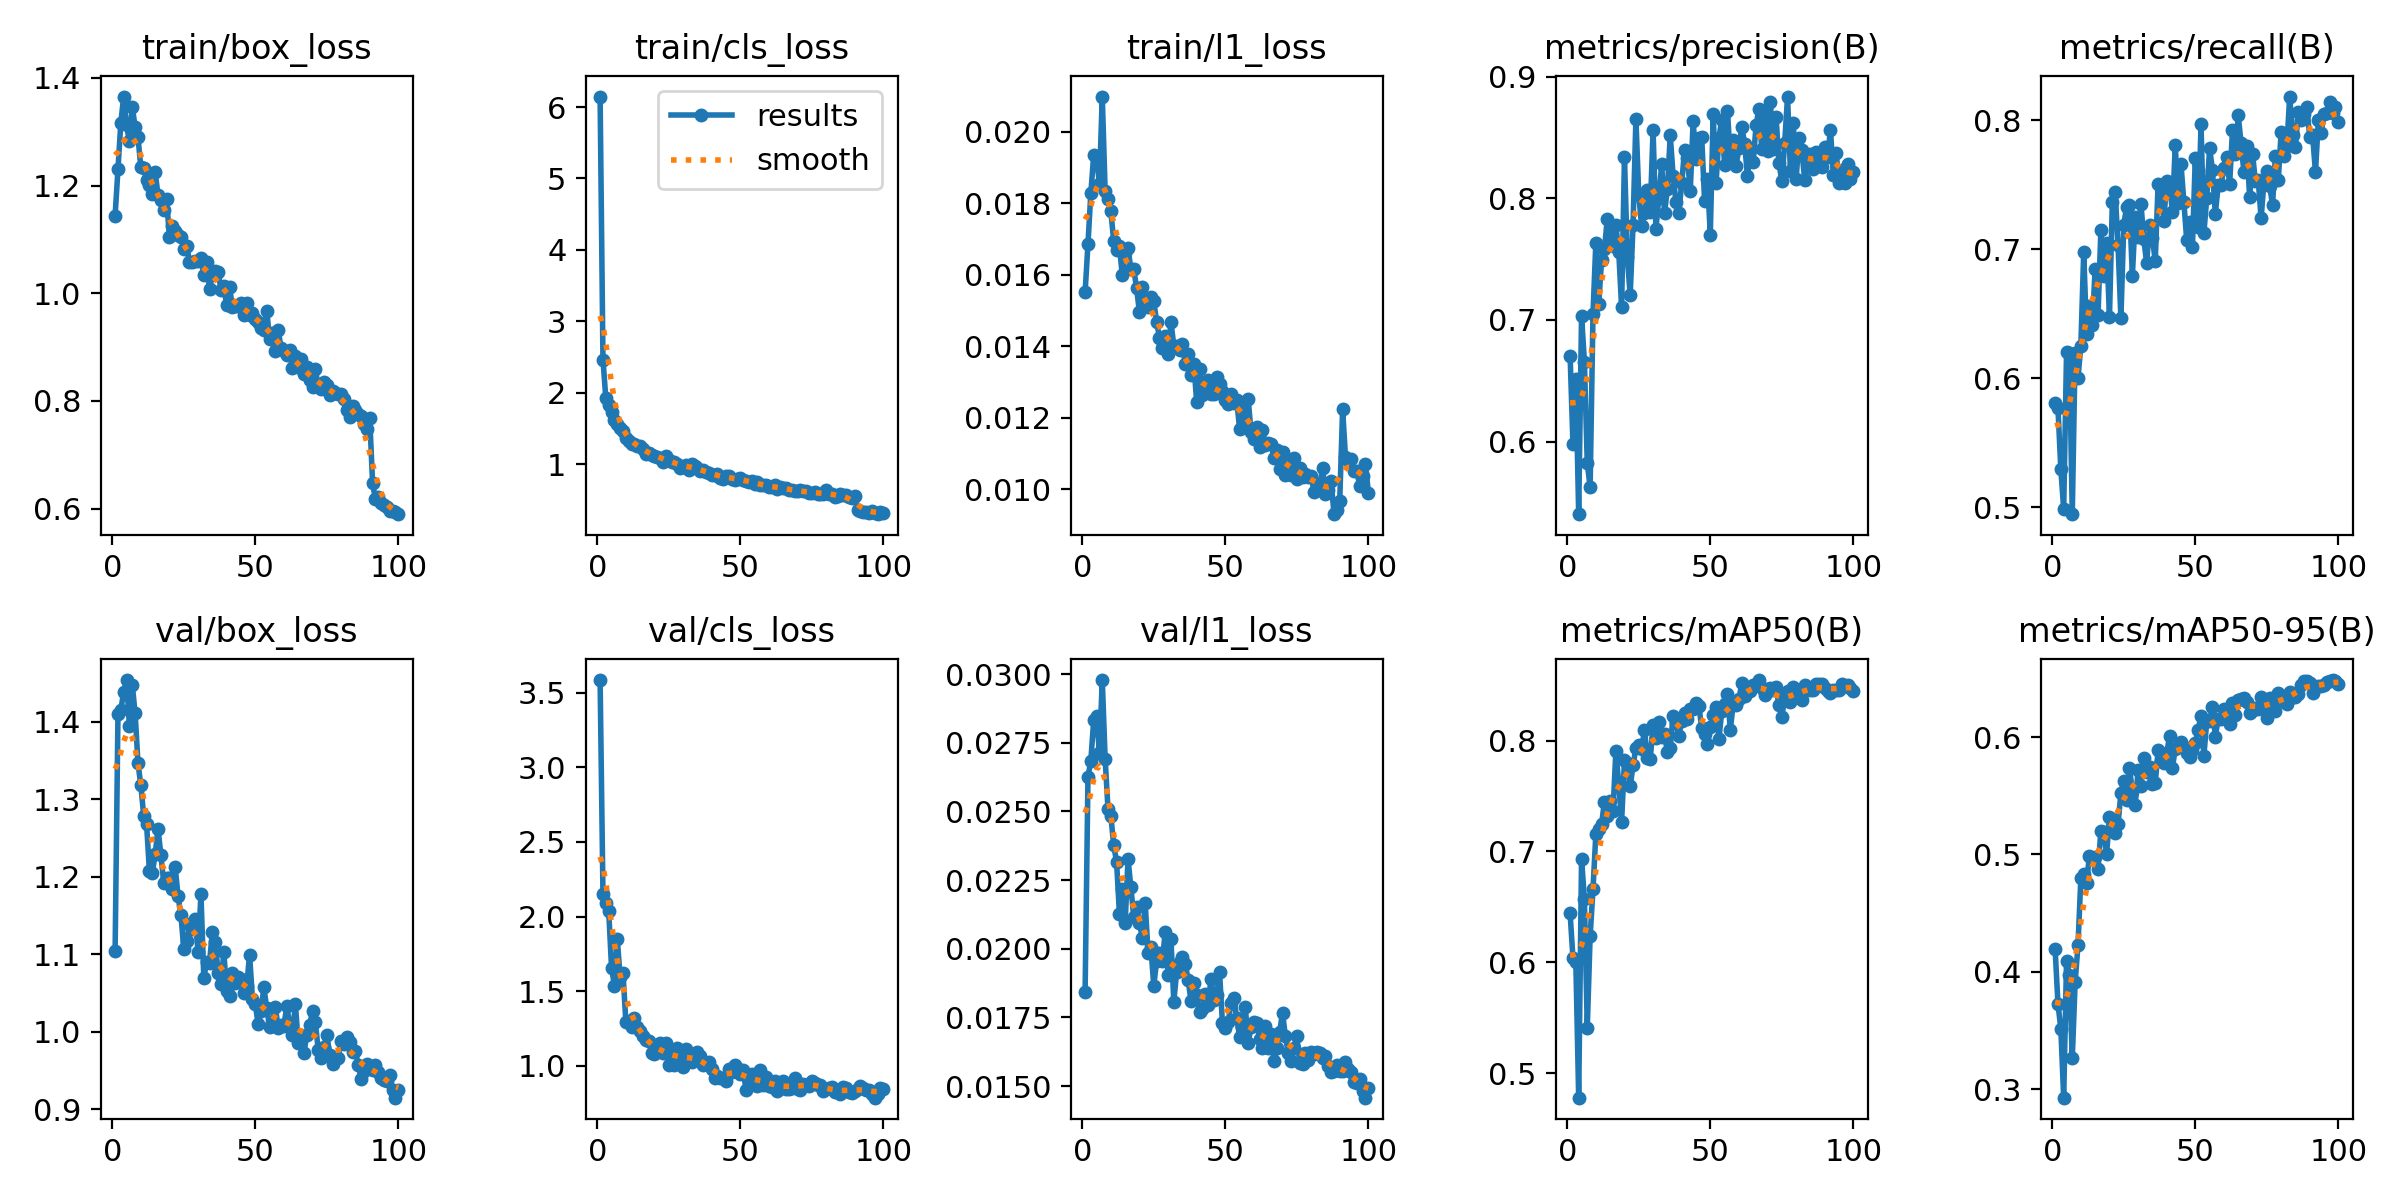

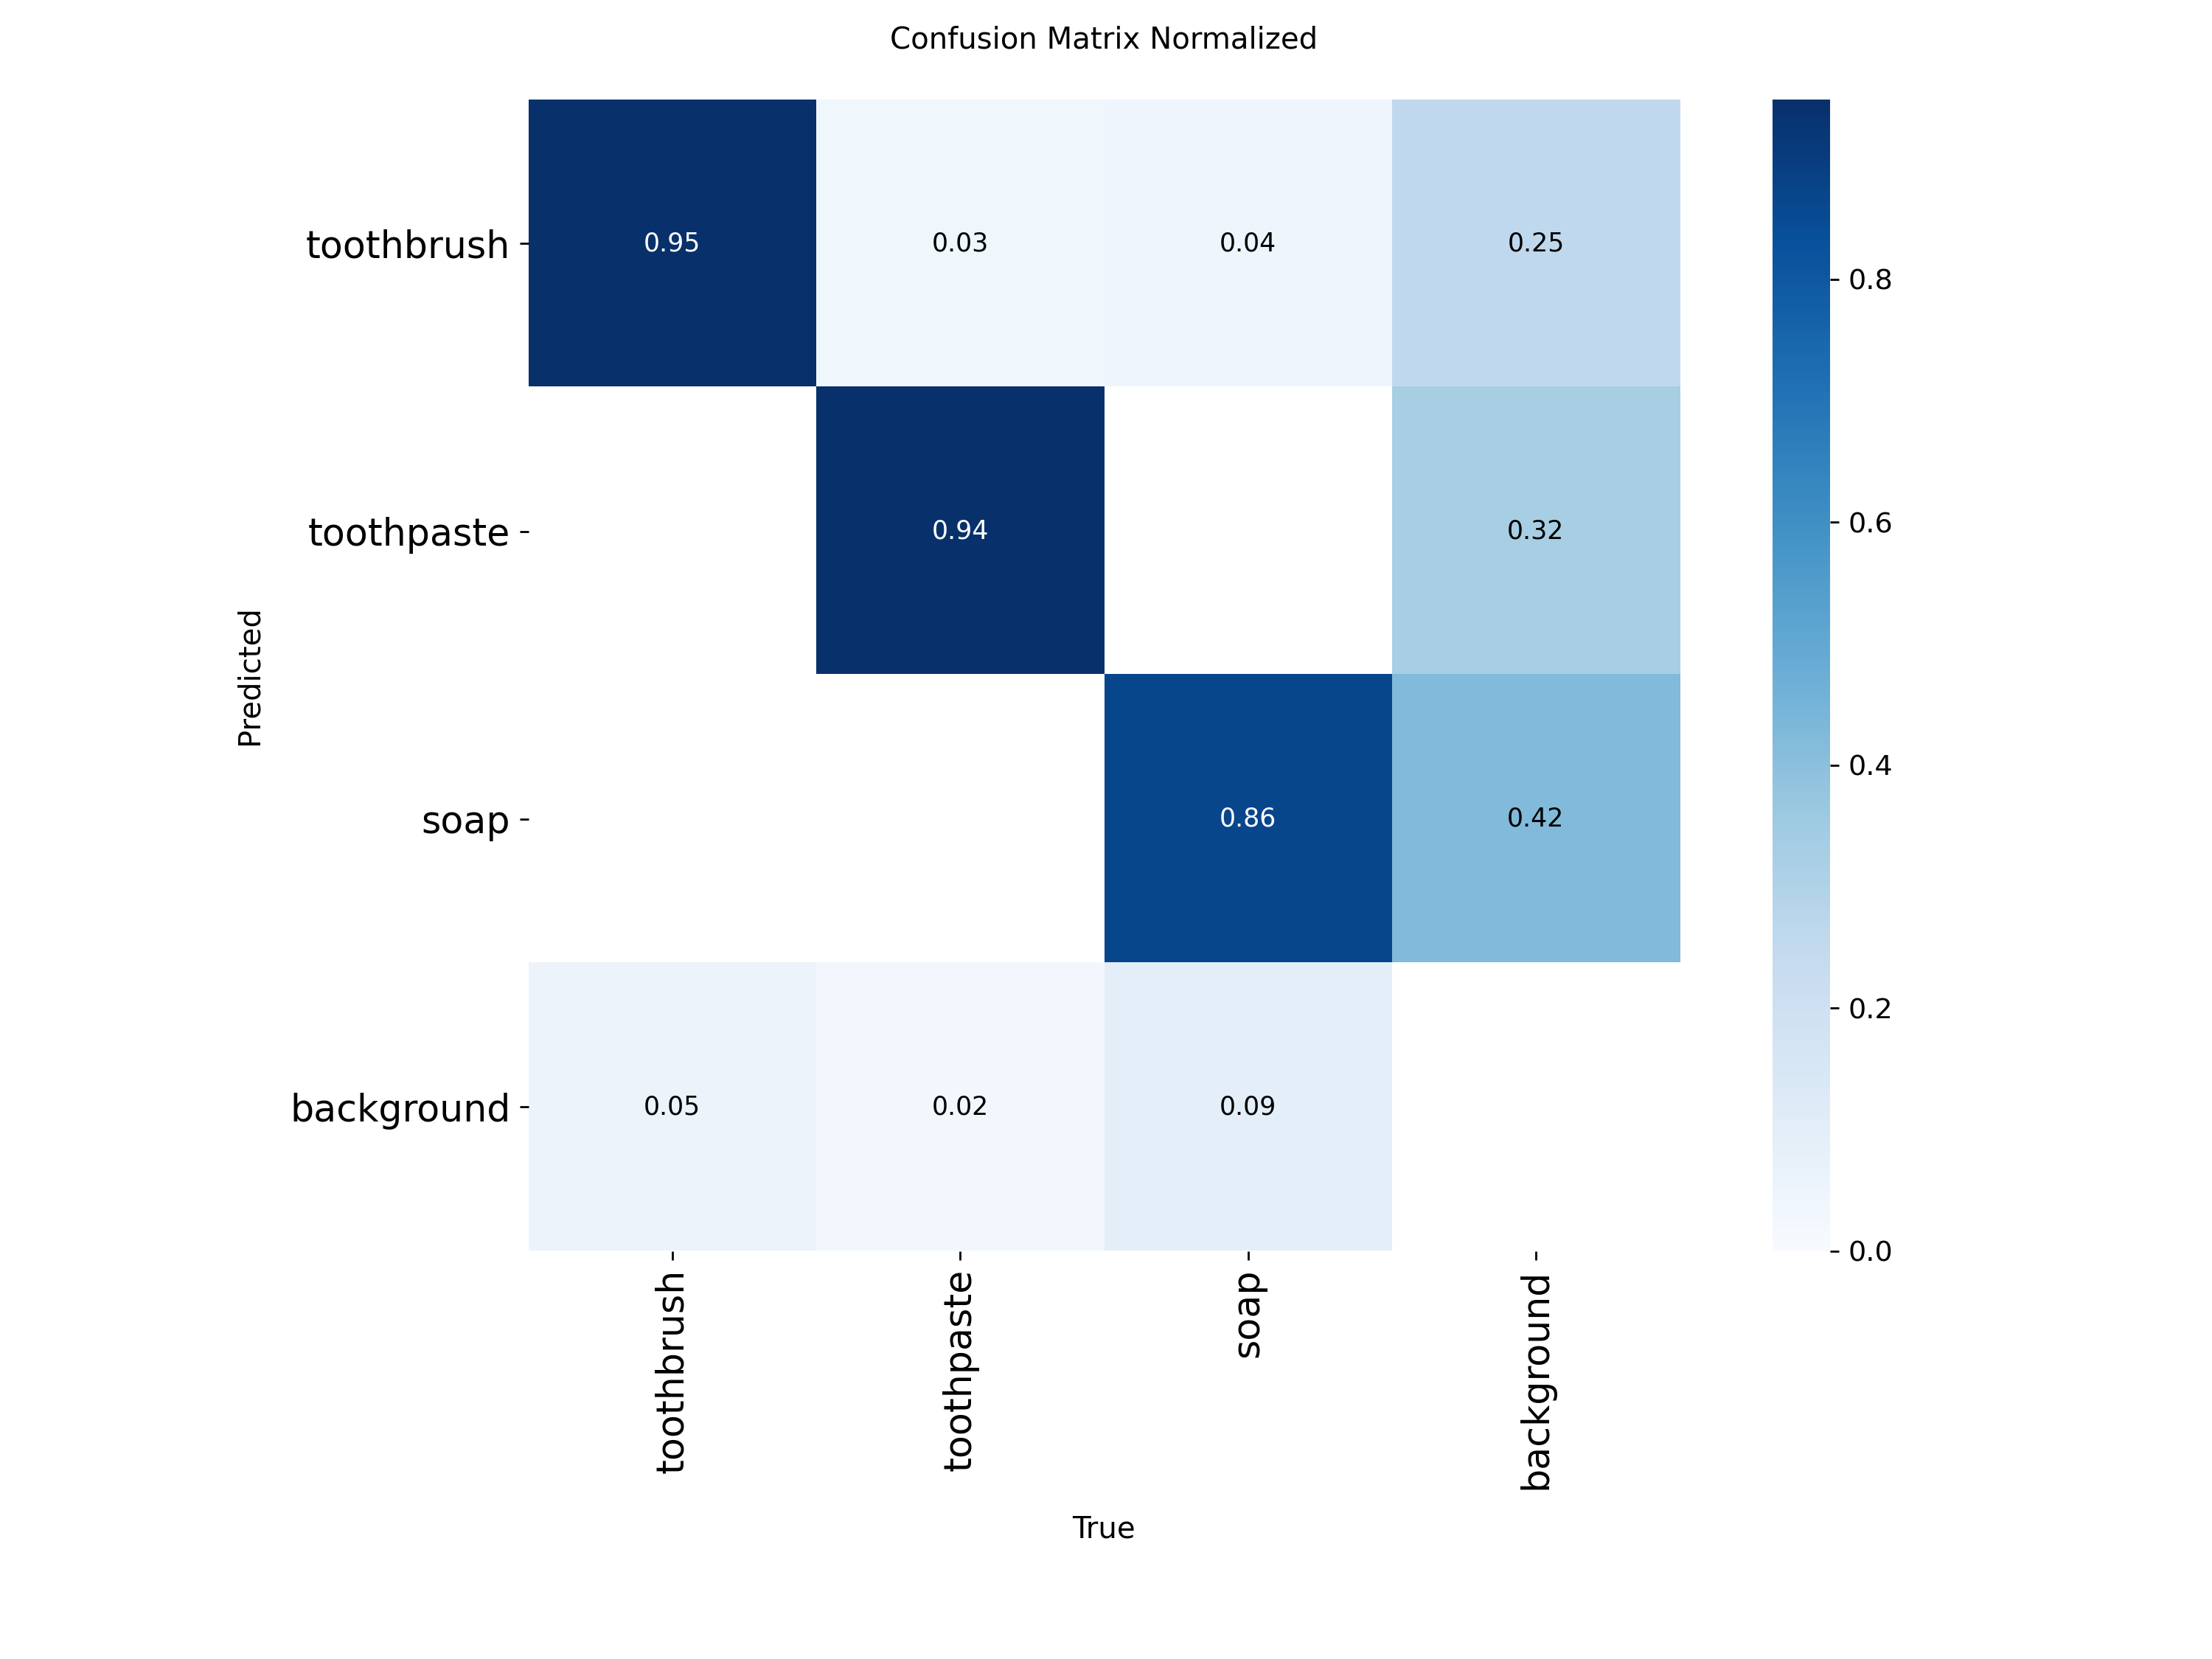

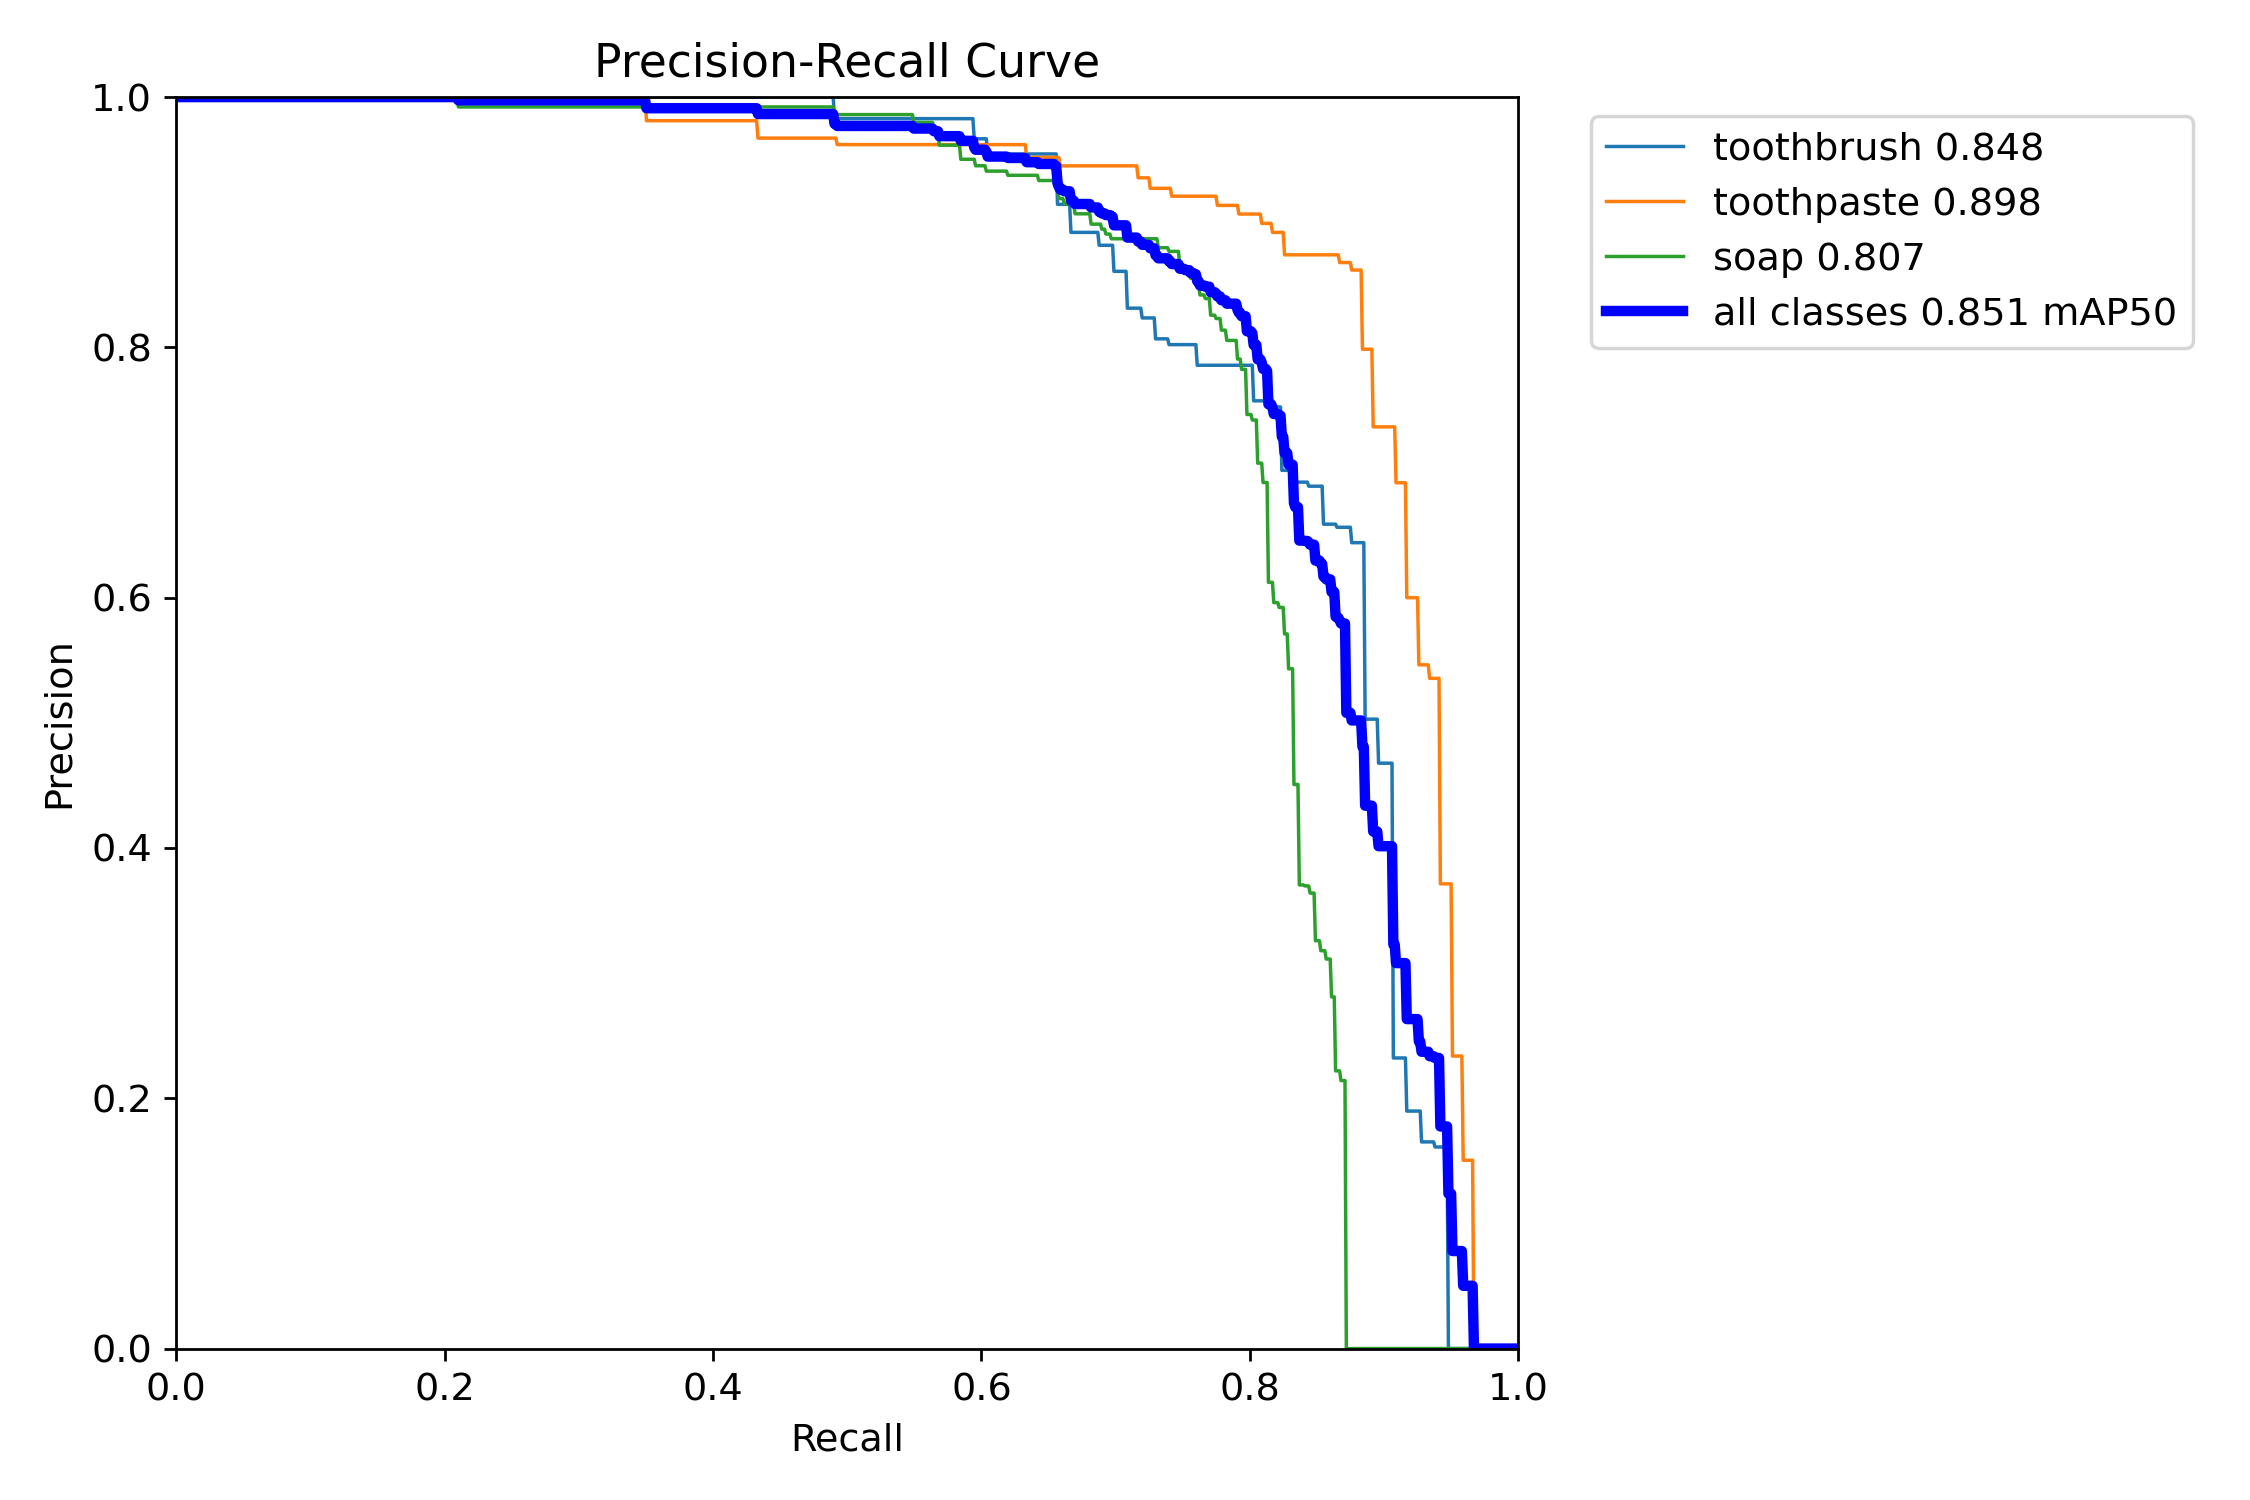

In [ ]:
# Кривые обучения и матрица ошибок эксперимента 1
from IPython.display import Image, display
for f in ['results.png', 'confusion_matrix_normalized.png', 'BoxPR_curve.png']:
    display(Image(f'/content/v1_3cls_results/content/runs/v1_3cls/{f}', width=800))

## 3. Эксперимент 2 — четыре класса с жидким мылом (`v2_4cls`)

Классы: `0 — toothbrush, 1 — toothpaste, 2 — soap, 3 — liquid_soap`.

**Перед запуском** на компьютере нужно пересобрать датасет с жидким мылом. Старый `prepared.zip` его **не содержит**: он собран без флага `--with-liquid`. Чтобы не затереть первый вариант, пишем в другую папку:

```
python scripts/merge_datasets.py --src-root dataset/raw_sources --out dataset/prepared_4cls --with-liquid
```

Затем упакуйте *содержимое* папки `dataset/prepared_4cls` (чтобы `images/` и `labels/` лежали в корне архива) в `prepared_4cls.zip` и загрузите в Colab.

In [ ]:
!rm -rf /content/prepared_4cls
!unzip -q /content/prepared_4cls.zip -d /content/prepared_4cls
!ls /content/prepared_4cls

data.yaml  docker_data.yaml  images  labels


In [ ]:
import yaml
cfg4 = dict(path='/content/prepared_4cls', train='images/train', val='images/val',
            names={0: 'toothbrush', 1: 'toothpaste', 2: 'soap', 3: 'liquid_soap'})
yaml.safe_dump(cfg4, open('/content/data_4cls.yaml', 'w'))

# Быстрая проверка: сколько рамок каждого класса в train/val
import glob, collections
for split in ['train', 'val']:
    cnt = collections.Counter()
    for f in glob.glob(f'/content/prepared_4cls/labels/{split}/*.txt'):
        for line in open(f):
            if line.strip():
                cnt[cfg4['names'][int(line.split()[0])]] += 1
    print(split, dict(cnt))

train {'soap': 1203, 'liquid_soap': 438, 'toothpaste': 773, 'toothbrush': 477}
val {'toothpaste': 149, 'toothbrush': 64, 'liquid_soap': 102, 'soap': 138}


In [ ]:
# Те же гиперпараметры, что и в эксперименте 1 — меняются только данные
!pip install ultralytics -qqq
!yolo detect train model=yolo26n.pt data=/content/data_4cls.yaml epochs=100 imgsz=640 batch=16 patience=25 seed=42 device=0 project=/content/runs name=v2_4cls

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_4cls.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freez

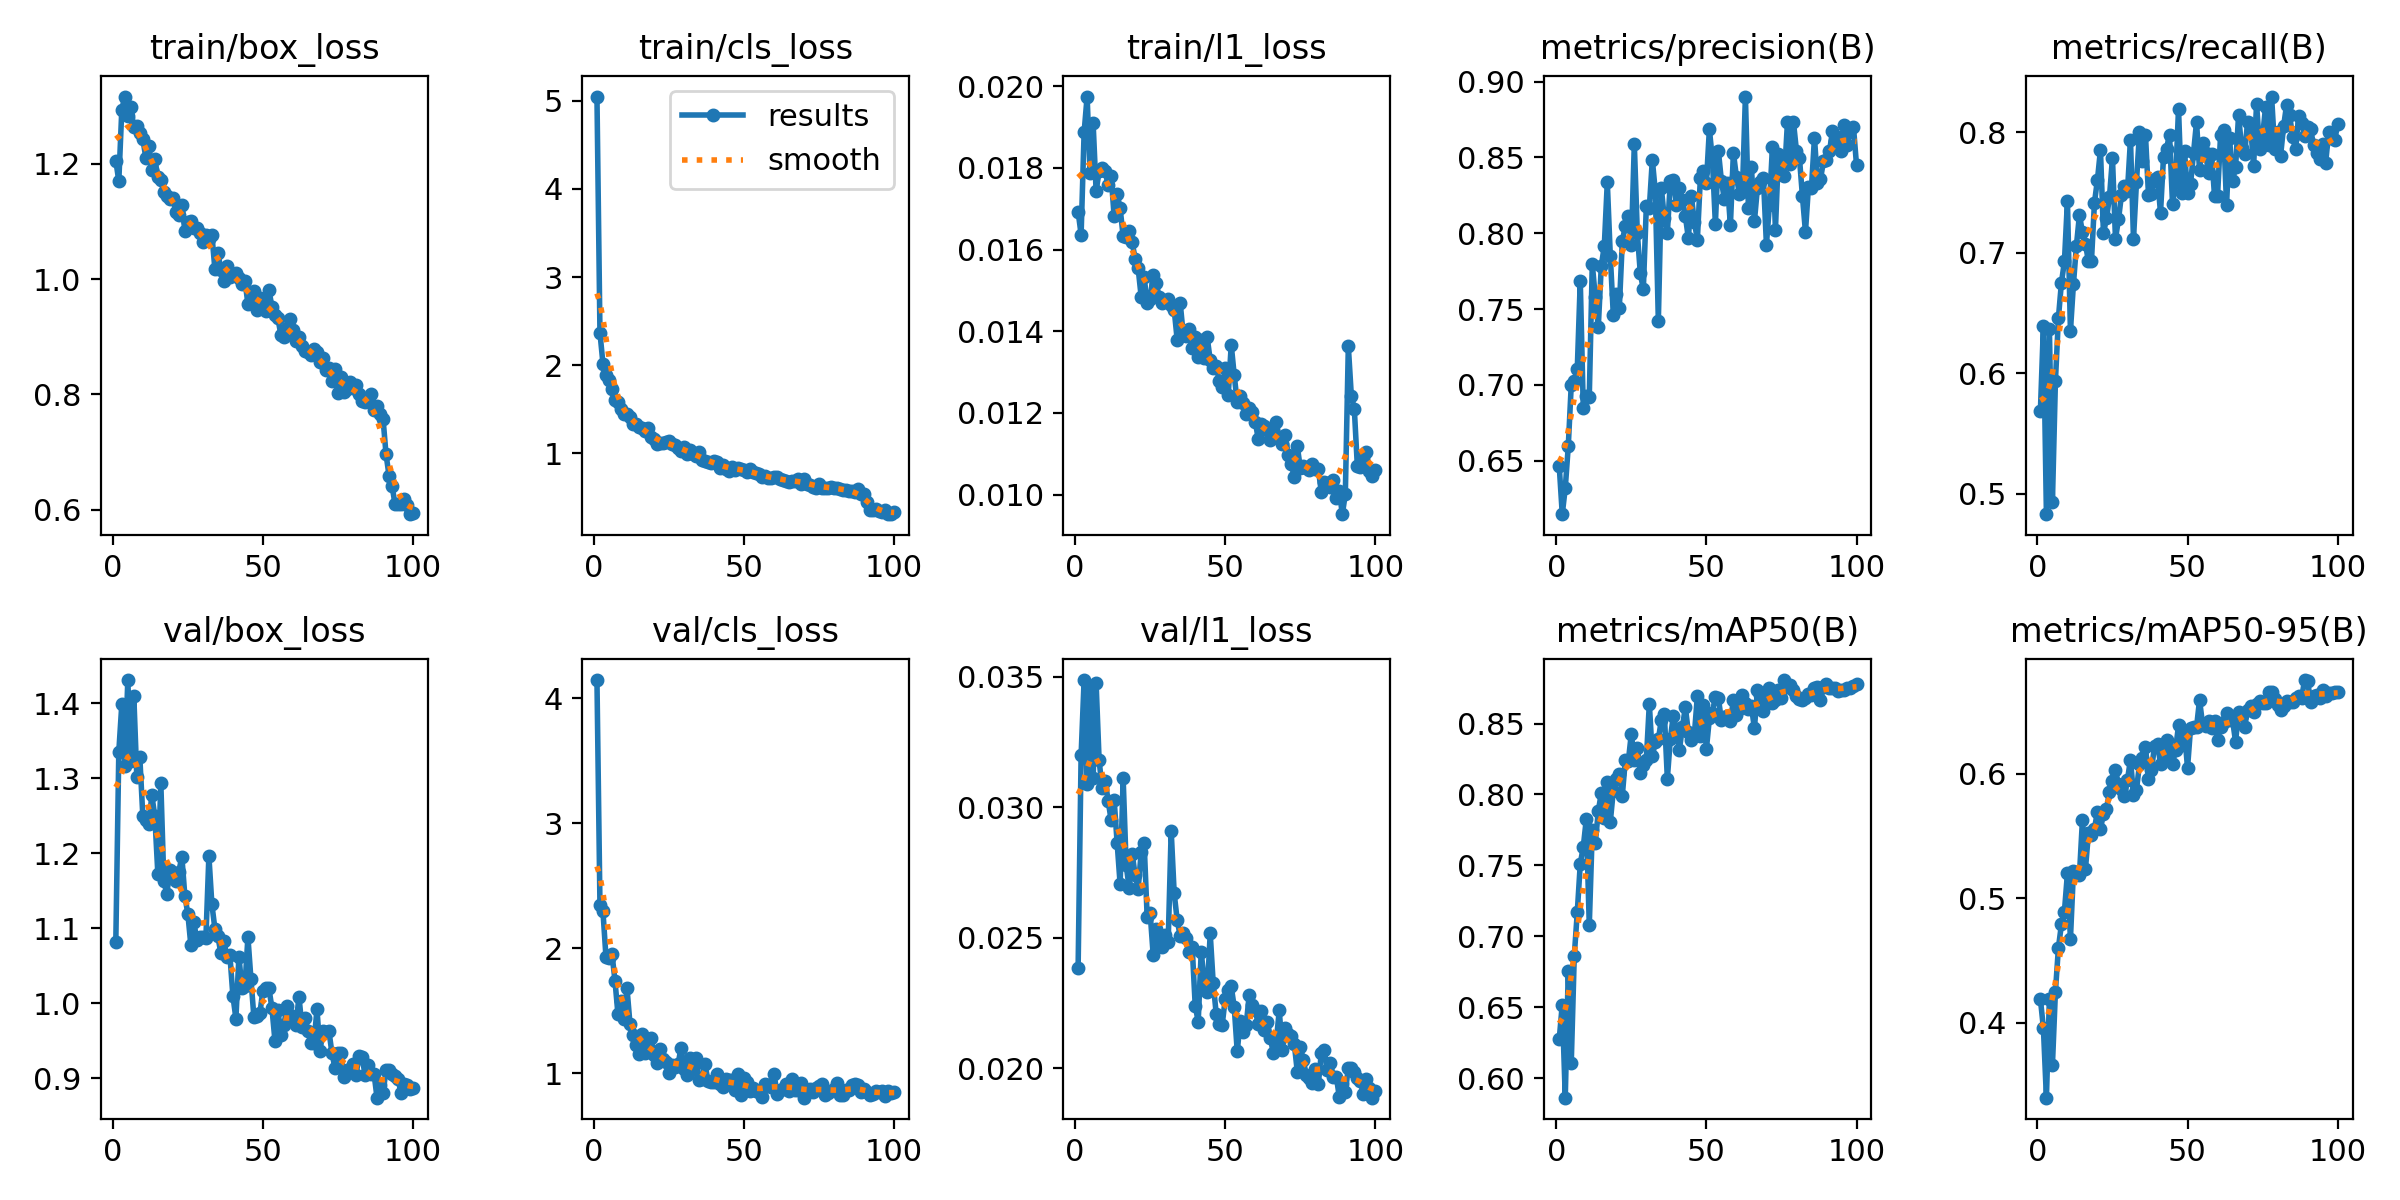

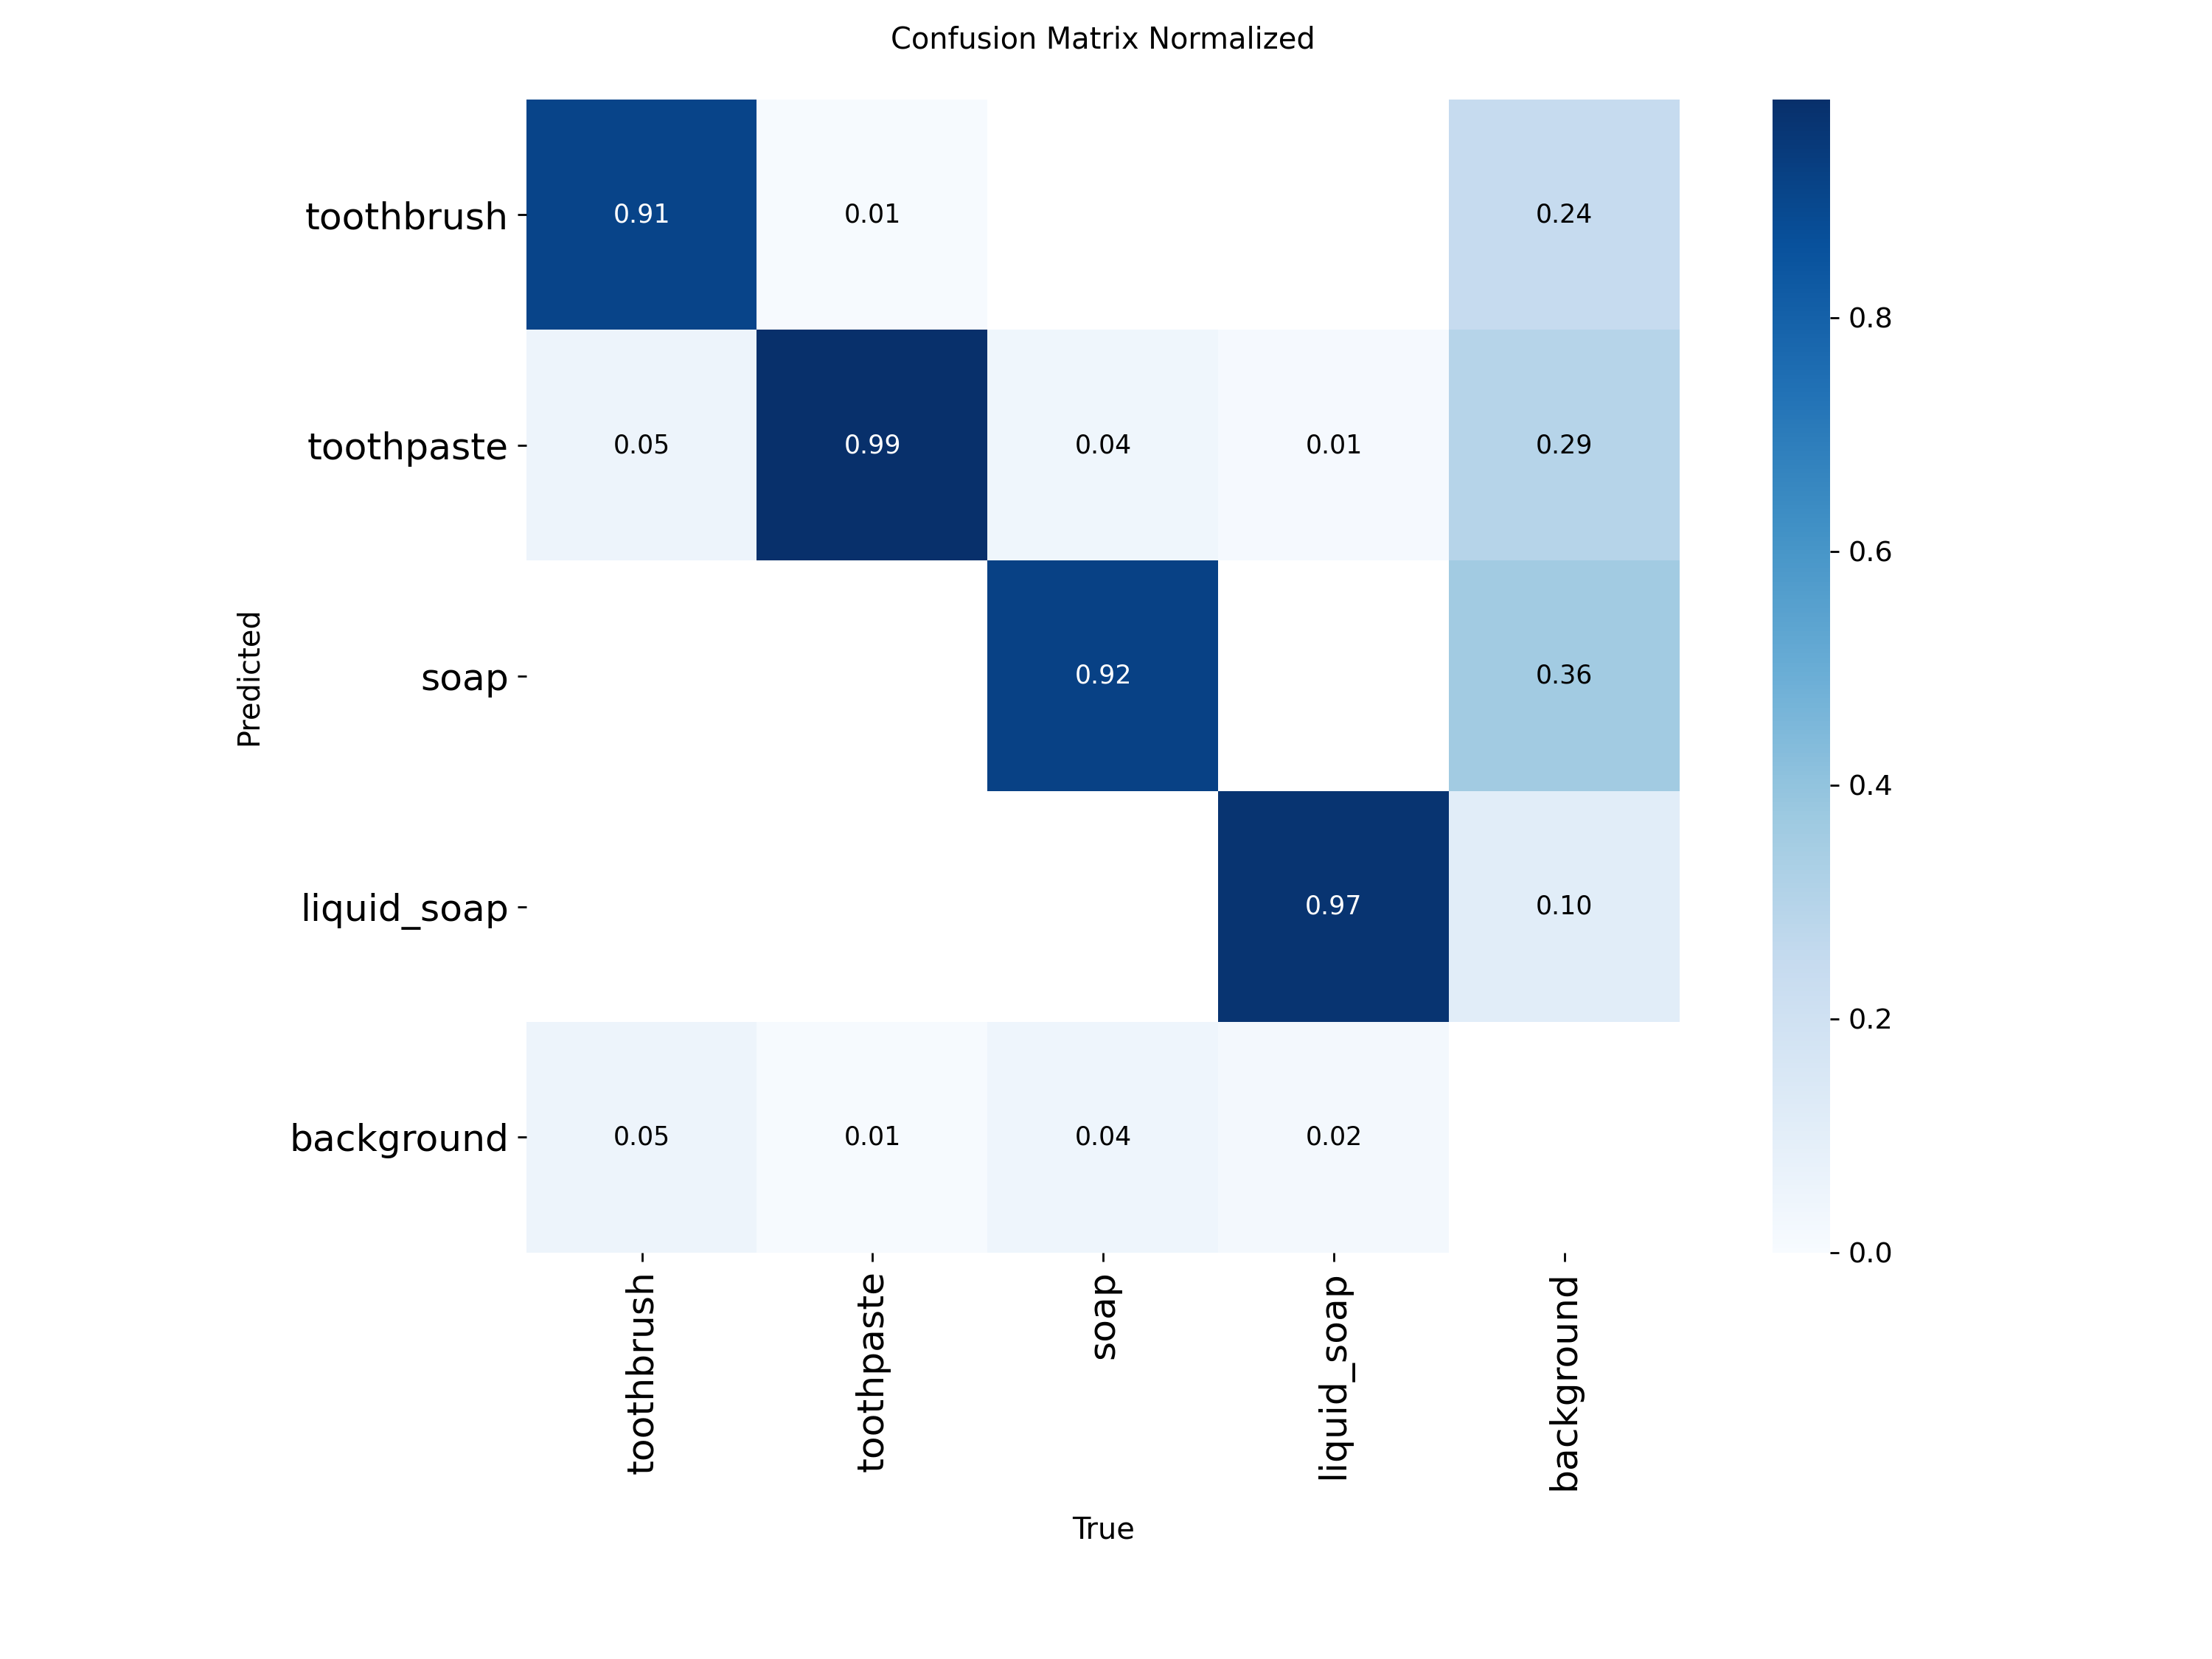

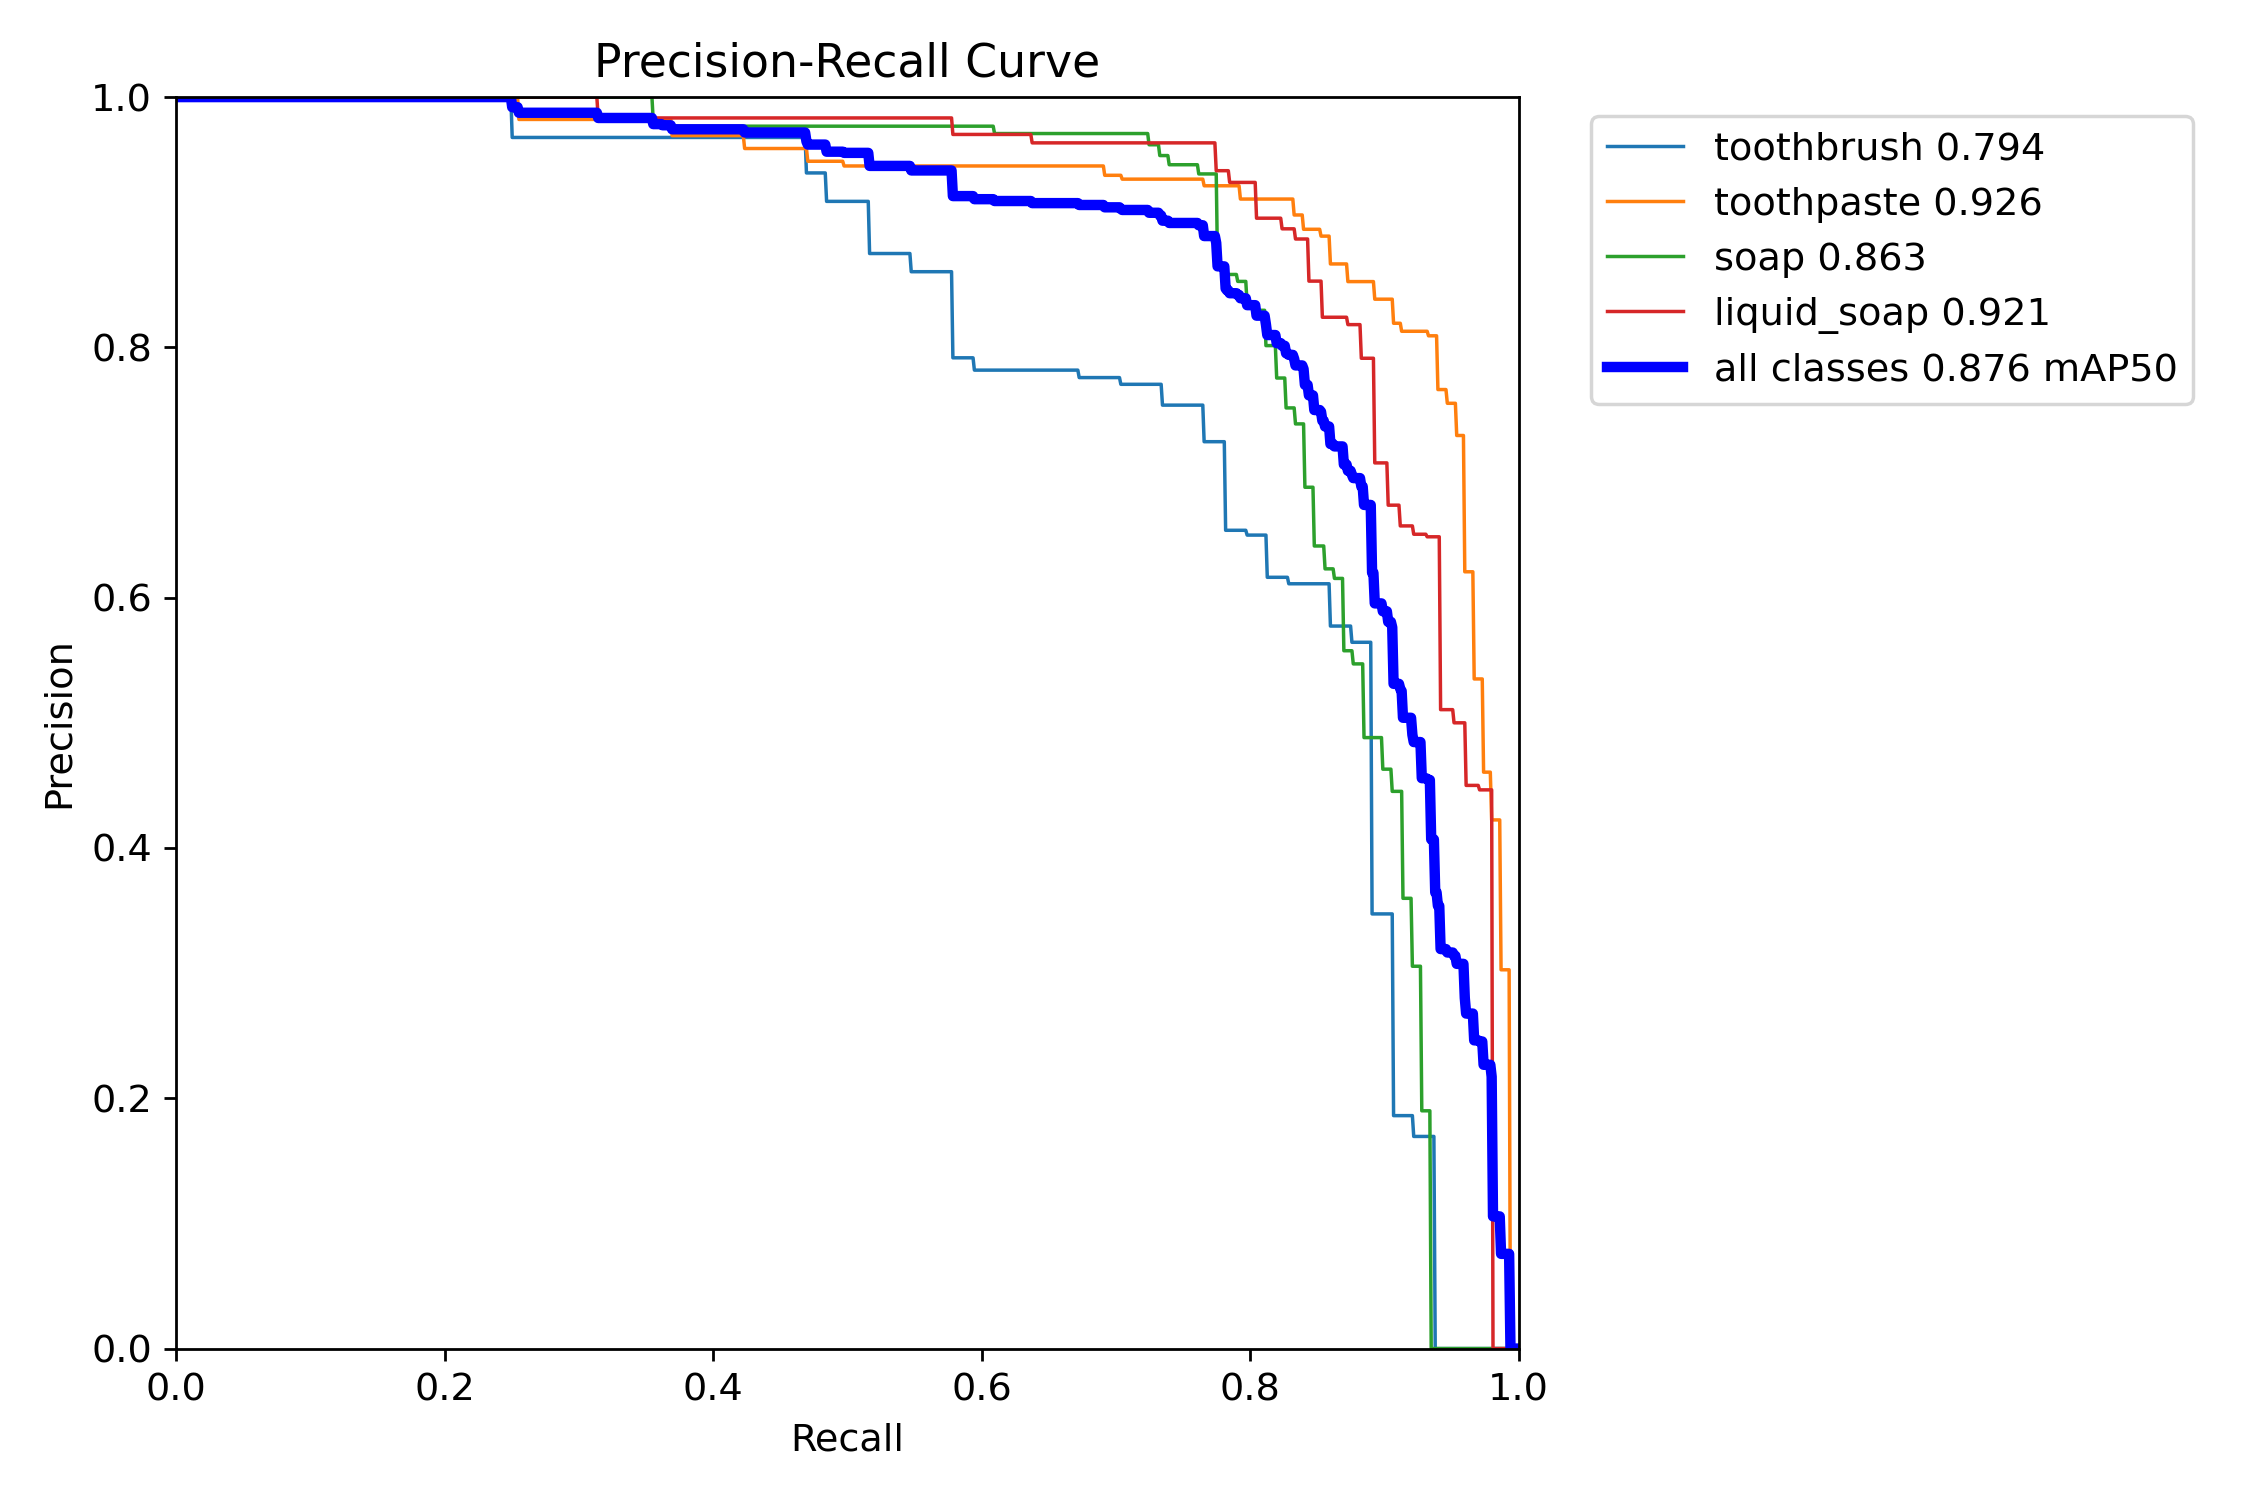

In [ ]:
for f in ['results.png', 'confusion_matrix_normalized.png', 'BoxPR_curve.png']:
    display(Image(f'/content/runs/v2_4cls/{f}', width=800))

## 4. Сравнение экспериментов

Считаем метрики по классам для обоих `best.pt`. **Важно:** валидационные наборы у экспериментов немного различаются (в 4-классовый добавлены кадры с жидким мылом), поэтому сравнение приблизительное. Решающее сравнение — на собственных тестовых фото.

In [ ]:
!unzip -q -o /content/prepared.zip -d /content/prepared
!ls /content/prepared
!ls /content/prepared/images

data.yaml  docker_data.yaml  images  labels
train  val


In [ ]:
import pandas as pd
from ultralytics import YOLO

def evaluate(weights, data_yaml):
    r = YOLO(weights).val(data=data_yaml, imgsz=640, plots=False, verbose=False)
    rows = []
    for k, ci in enumerate(r.box.ap_class_index):
        p, rc, ap50, ap = r.box.class_result(k)
        rows.append({'class': r.names[int(ci)], 'P': p, 'R': rc, 'mAP50': ap50, 'mAP50-95': ap})
    rows.append({'class': 'all', 'P': r.box.mp, 'R': r.box.mr, 'mAP50': r.box.map50, 'mAP50-95': r.box.map})
    return pd.DataFrame(rows).set_index('class').round(3)

res1 = evaluate('/content/v1_3cls_results/content/runs/v1_3cls/weights/best.pt', '/content/data.yaml')
res2 = evaluate('/content/runs/v2_4cls/weights/best.pt', '/content/data_4cls.yaml')
print('v1_3cls'); display(res1)
print('v2_4cls'); display(res2)

summary = pd.DataFrame({'v1_3cls': res1['mAP50'], 'v2_4cls': res2['mAP50']})
display(summary)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1033.7±282.3 MB/s, size: 32.8 KB)
val: Scanning /content/prepared/labels/val... 189 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 189/189 1.9Kit/s 0.1s
val: New cache created: /content/prepared/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 6.4it/s 1.9s
                   all        189        473       0.82      0.815      0.846      0.646
Speed: 1.1ms preprocess, 3.9ms inference, 0.0ms loss, 1.4ms postprocess per image
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1266.5±270.8 MB/s, size: 29.3 KB)
val: Scanning /co

,P,R,mAP50,mAP50-95
class,,,,
toothbrush,0.737,0.823,0.847,0.616
toothpaste,0.853,0.875,0.893,0.627
soap,0.869,0.747,0.799,0.696
all,0.820,0.815,0.846,0.646


v2_4cls


,P,R,mAP50,mAP50-95
class,,,,
toothbrush,0.757,0.734,0.793,0.568
toothpaste,0.885,0.859,0.926,0.662
soap,0.849,0.790,0.864,0.795
liquid_soap,0.939,0.784,0.919,0.668
all,0.858,0.792,0.876,0.673


,v1_3cls,v2_4cls
class,,
all,0.846,0.876
liquid_soap,NaN,0.919
soap,0.799,0.864
toothbrush,0.847,0.793
toothpaste,0.893,0.926


## 5. Экспорт в LiteRT

Ultralytics экспортирует модель через `litert-torch`. На выходе вход `[1, 3, 640, 640]` (каналы первыми, NCHW) и выход `[1, 4 + число_классов, 8400]`: для трёх классов `[1, 7, 8400]`, для четырёх `[1, 8, 8400]`. Координаты нормализованы в 0..1, оценки классов уже прошли сигмоиду; NMS выполняется в приложении (`nms=None`).

In [ ]:
from ultralytics import YOLO
m = YOLO('/content/runs/v1_3cls/weights/best.pt')
p = m.export(format='litert', imgsz=640, nms=None, device='cpu')  # если ошибка формата, попробуй format='tflite'
print(p)
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    from tensorflow.lite.python.interpreter import Interpreter
it = Interpreter(model_path=str(p)); it.allocate_tensors()
print(it.get_input_details()[0]['shape'], it.get_output_details()[0]['shape'])
from google.colab import files; files.download(str(p))

LiteRT: export success ✅ 28.5s, saved as '/content/runs/v1_3cls/weights/best.tflite' (9.4 MB)
/content/runs/v1_3cls/weights/best.tflite
[  1   3 640 640] [   1    7 8400]


Проверка файла модели вне Android: прогоняем тестовое фото через `best.tflite` и смотрим диапазоны координат и оценки классов (картинку нужно подать в формате NCHW). Для эксперимента 1 на фото со щёткой получено `toothbrush ≈ 0.86`, остальные ≈ 0.

In [ ]:
import numpy as np
from PIL import Image
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    from tensorflow.lite.python.interpreter import Interpreter
it = Interpreter(model_path='/content/best.tflite'); it.allocate_tensors()
inp = it.get_input_details()[0]; out = it.get_output_details()[0]
x = np.asarray(Image.open('/content/photo.jpg').convert('RGB').resize((640, 640)), np.float32) / 255.
it.set_tensor(inp['index'], np.transpose(x, (2, 0, 1))[None]); it.invoke()
y = it.get_tensor(out['index'])[0]
print('cx max', y[0].max(), 'w max', y[2].max())
print('max score по классам', y[4:].max(axis=1))

cx max 0.9950426 w max 0.84910434
max score по классам [8.6451900e-01 1.5818398e-03 1.3442886e-04]


Для четырёхклассовой модели экспорт делается так же:

In [ ]:
m4 = YOLO('/content/runs/v2_4cls/weights/best.pt')
p4 = m4.export(format='litert', imgsz=640, nms=None, device='cpu')
print(p4)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/content/runs/v2_4cls/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 8, 8400) (5.2 MB)
requirements: Ultralytics requirements ['litert-torch>=0.10.0', 'ai-edge-litert>=2.3.0'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 86 packages in 590ms
Prepared 16 packages in 5.09s
Uninstalled 4 packages in 35ms
Installed 16 packages in 49ms
 + ai-edge-litert==2.3.0
 + ai-edge-quantizer==0.10.1
 - anyio==4.16.0
 + anyio==4.14.2
 + backports-strenum==1.3.1
 + fire==0.7.1
 - immutabledict==4.3.1
 + immutabledict==4.2.1
 + jaxtyping==0.3.11
 + litert-converter==0.5.0
 + litert-lm-builder==0.19.2


/usr/local/lib/python3.13/dist-packages/torchao/quantization/quant_api.py:1558: SyntaxWarning: invalid escape sequence '\.'
  * regex for parameter names, must start with `re:`, e.g. `re:language\.layers\..+\.q_proj.weight`.
W1118 10:37:17.737000 385 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.



LiteRT: starting export with litert_torch 0.10.0...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:02) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

... (18 outputs left out)

(00:17) [ DONE] LiteRT-Torch Convert (+00:17)

(00:00) [START] Write Model to /content/runs/v2_4cls/weights/best.tflite

(00:00) [ DONE] Write Model to /content/runs/v2_4cls/weights/best.tflite (+00:00)

LiteRT: export success ✅ 26.6s, saved as '/content/runs/v2_4cls/weights/best.tflite' (9.4 MB)

Export complete (26.9s)
Results saved to /content/runs/v2_4cls/weights/best.tflite
Predict:         yolo predict task=detect model=/content/runs/v2_4cls/weights/best.tflite imgsz=640 
Validate:        yolo val task=detect model=/content/runs/v2_4cls/weights/best.tflite imgsz=640 data=/content/data_4cls.yaml 
Visualize:       https://netron.app
/content/runs/v2_4cls/weights/best.tflite


In [ ]:
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    from tensorflow.lite.python.interpreter import Interpreter
it = Interpreter(model_path=str(p4)); it.allocate_tensors()
print(it.get_input_details()[0]['shape'], it.get_output_details()[0]['shape'])
from google.colab import files; files.download(str(p4))

[  1   3 640 640] [   1    8 8400]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
from PIL import Image
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    from tensorflow.lite.python.interpreter import Interpreter
it = Interpreter(model_path='/content/best.tflite'); it.allocate_tensors()
inp = it.get_input_details()[0]; out = it.get_output_details()[0]
x = np.asarray(Image.open('/content/photo.jpg').convert('RGB').resize((640, 640)), np.float32) / 255.
it.set_tensor(inp['index'], np.transpose(x, (2, 0, 1))[None]); it.invoke()
y = it.get_tensor(out['index'])[0]
print('cx max', y[0].max(), 'w max', y[2].max())
print('max score по классам', y[4:].max(axis=1))

cx max 0.9924865 w max 0.8030958
max score по классам [ 0.00013769   0.0016978  0.00032825     0.90385]


## 6. Сохранение результатов

Файлы в `/content` исчезают после сброса среды, поэтому копируем результаты на Google Drive и (или) скачиваем архивом.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/lab2_neiro
!cp -r /content/v1_3cls_results/content/runs/v1_3cls /content/drive/MyDrive/lab2_neiro/
!cp -r /content/runs/v2_4cls /content/drive/MyDrive/lab2_neiro/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 1. Упаковываем папку в архив
!zip -r /content/v1_3cls_results.zip /content/runs/v1_3cls

# 2. Запускаем скачивание архива
from google.colab import files
files.download('/content/v1_3cls_results.zip')

  adding: content/runs/v1_3cls/ (stored 0%)
  adding: content/runs/v1_3cls/results.png (deflated 7%)
  adding: content/runs/v1_3cls/BoxPR_curve.png (deflated 14%)
  adding: content/runs/v1_3cls/train_batch2.jpg (deflated 3%)
  adding: content/runs/v1_3cls/train_batch0.jpg (deflated 3%)
  adding: content/runs/v1_3cls/confusion_matrix_normalized.png (deflated 26%)
  adding: content/runs/v1_3cls/BoxR_curve.png (deflated 12%)
  adding: content/runs/v1_3cls/labels.jpg (deflated 29%)
  adding: content/runs/v1_3cls/val_batch1_pred.jpg (deflated 20%)
  adding: content/runs/v1_3cls/val_batch1_labels.jpg (deflated 21%)
  adding: content/runs/v1_3cls/val_batch2_pred.jpg (deflated 9%)
  adding: content/runs/v1_3cls/train_batch6120.jpg (deflated 16%)
  adding: content/runs/v1_3cls/results.csv (deflated 63%)
  adding: content/runs/v1_3cls/val_batch0_pred.jpg (deflated 17%)
  adding: content/runs/v1_3cls/weights/ (stored 0%)
  adding: content/runs/v1_3cls/weights/best.pt (deflated 11%)
  adding: cont

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>